# Systemy AI – Laboratorium 6
## Zadanie: klasyfikator recenzji IMDB na pełnym zbiorze

Zbuduj klasyfikator nastroju recenzji (pozytywna / negatywna) na **pełnym** zbiorze IMDB: 25 000 recenzji treningowych i 25 000 testowych. Wzoruj się na notatniku `SystemyAI_Lab6_IMDB_wzor.ipynb`; cały kod piszesz sam(a).

**Czas obliczeń.** Zbiór jest 5 razy większy niż we wzorze. Pojedyncza walidacja krzyżowa trwa kilkanaście–kilkadziesiąt sekund, strojenie w punkcie 4 – kilka minut. Dlatego używamy **3 rund** walidacji krzyżowej zamiast 5.

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Wczytanie i czyszczenie
1. Wczytaj zbiór `stanfordnlp/imdb` z Hugging Face do `train_df` i `test_df` (kolumny `text`, `label`). Skopiuj z wzoru wersję z zapasowym wczytaniem z GitHuba.
2. Zamień `<br />` na spacje w obu zbiorach.
3. Policz `class_share` (udział klas w `train_df`) i `median_words` (mediana liczby słów w recenzji treningowej).

In [1]:
# Twoje rozwiązanie

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

try:
    from datasets import load_dataset
    imdb = load_dataset("stanfordnlp/imdb")
    print(imdb)
    train_df = imdb["train"].to_pandas()
    test_df = imdb["test"].to_pandas()
except Exception as e:
    print("Hugging Face niedostępny – wczytuję kopię z GitHuba.", type(e).__name__)
    URL = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"
    df = pd.read_csv(URL).rename(columns={"review": "text"})
    df["label"] = (df["sentiment"] == "positive").astype(int)
    train_df, test_df = train_test_split(df[["text", "label"]], test_size=0.5,
                                         stratify=df["label"], random_state=0)

print(train_df.shape, test_df.shape)


def wyczysc(teksty):
    return teksty.str.replace("<br />", " ", regex=False)


train_df["text"] = wyczysc(train_df["text"])
test_df["text"] = wyczysc(test_df["text"])

class_share = train_df["label"].value_counts(normalize=True)
print(class_share)

median_words = train_df["text"].str.split().str.len().median()
print("mediana słów w recenzji:", median_words)


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})
(25000, 2) (25000, 2)
label
0    0.5
1    0.5
Name: proportion, dtype: float64
mediana słów w recenzji: 173.0


In [2]:
# TEST
assert train_df.shape == (25000, 2) and test_df.shape == (25000, 2)
assert abs(class_share[1] - 0.5) < 0.01
assert not train_df["text"].str.contains("<br />").any()
assert 150 < median_words < 200
print("1 OK")

1 OK


---
## 2. Porównanie trzech klasyfikatorów
1. Utwórz `cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)`.
2. Dla pipeline'ów `TfidfVectorizer()` + klasyfikator: `MultinomialNB()`, `LinearSVC()`, `LogisticRegression(max_iter=1000)` policz `cross_validate` na **całym** zbiorze treningowym.
3. Wyniki zbierz w tabeli `porownanie` (indeks: `"naiwny Bayes"`, `"liniowy SVM"`, `"regresja logistyczna"`; kolumny: `"CV"`, `"CV odch."`, `"czas uczenia [s]"`).

In [3]:
# Twoje rozwiązanie

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

X_train, y_train = train_df["text"], train_df["label"]

klasyfikatory = {
    "naiwny Bayes": MultinomialNB(),
    "liniowy SVM": LinearSVC(),
    "regresja logistyczna": LogisticRegression(max_iter=1000),
}

wiersze = []
for nazwa, klf in klasyfikatory.items():
    r = cross_validate(make_pipeline(TfidfVectorizer(), klf), X_train, y_train, cv=cv)
    wiersze.append({"model": nazwa, "CV": r["test_score"].mean(), "CV odch.": r["test_score"].std(),
                    "czas uczenia [s]": r["fit_time"].mean()})

porownanie = pd.DataFrame(wiersze).set_index("model")
porownanie.round(3)


,CV,CV odch.,czas uczenia [s]
model,,,
naiwny Bayes,0.862,0.002,2.470
liniowy SVM,0.893,0.001,2.733
regresja logistyczna,0.885,0.002,3.690


In [4]:
# TEST
assert list(porownanie.index) == ["naiwny Bayes", "liniowy SVM", "regresja logistyczna"]
assert porownanie["CV"].between(0.83, 0.92).all()
assert porownanie.loc["liniowy SVM", "CV"] > porownanie.loc["naiwny Bayes", "CV"]
print("2 OK")

2 OK


*Twoja odpowiedź:* porównaj wyniki z wynikami z wzoru (podzbiór 5000 recenzji). Co dało pięciokrotne zwiększenie zbioru treningowego? Czy kolejność modeli się zmieniła?

Każdy model zyskał ok. 3–4 p.p. (SVM 0,862 -> 0,893), a odchylenie w CV jest mniejsze. Kolejność się nie zmieniła.

---
## 3. Strojenie: `GridSearchCV`
Dostrój pipeline `TfidfVectorizer(min_df=2)` + `LinearSVC()`:
- `tfidfvectorizer__ngram_range` ∈ {(1, 1), (1, 2)},
- `linearsvc__C` ∈ {0.1, 1}.

Obiekt zapisz w `gs` (z `cv=cv`), wypisz `best_params_` i `best_score_`. **To potrwa kilka minut** – w tym czasie odpowiedz na pytanie pod komórką.

In [5]:
# Twoje rozwiązanie

from sklearn.model_selection import GridSearchCV

siatka = {
    "tfidfvectorizer__ngram_range": [(1, 1), (1, 2)],
    "linearsvc__C": [0.1, 1],
}

gs = GridSearchCV(make_pipeline(TfidfVectorizer(min_df=2), LinearSVC()), siatka, cv=cv)
gs.fit(X_train, y_train)

print("best_params_:", gs.best_params_)
print(f"best_score_: {gs.best_score_:.3f}")

wyniki_gs = pd.DataFrame(gs.cv_results_)[["param_tfidfvectorizer__ngram_range", "param_linearsvc__C",
                                          "mean_test_score", "mean_fit_time"]]
wyniki_gs.round(3)


best_params_: {'linearsvc__C': 1, 'tfidfvectorizer__ngram_range': (1, 2)}
best_score_: 0.906


,param_tfidfvectorizer__ngram_range,param_linearsvc__C,mean_test_score,mean_fit_time
0,"(1, 1)",0.1,0.888,2.396
1,"(1, 2)",0.1,0.889,7.958
2,"(1, 1)",1.0,0.892,2.469
3,"(1, 2)",1.0,0.906,8.200


In [6]:
# TEST
assert gs.best_params_["tfidfvectorizer__ngram_range"] == (1, 2), "Na pełnym zbiorze bigramy powinny pomagać"
assert gs.best_score_ > porownanie.loc["liniowy SVM", "CV"]
print("3 OK")

3 OK


*Twoja odpowiedź:* we wzorze bigramy na 5000 recenzjach nic nie dały. Czy na pełnym zbiorze jest inaczej? Dlaczego większy zbiór pomaga właśnie bigramom? Ile razy wolniej uczy się model z bigramami i dlaczego?

Tak, bigramy podniosły wynik z 0,892 do 0,906. Pary słów występują rzadko, więc dopiero na dużym zbiorze pojawiają się wystarczająco często, żeby model nauczył się ich wag. Model z bigramami uczy się ok. 3 razy wolniej, bo ma dużo większy słownik.

---
## 4. Ocena końcowa
`model_koncowy = gs.best_estimator_`. Policz `acc_test` (accuracy na **całym** zbiorze testowym – jedyny raz, kiedy go używasz), narysuj macierz pomyłek i wypisz `classification_report`.

accuracy (test): 0.903


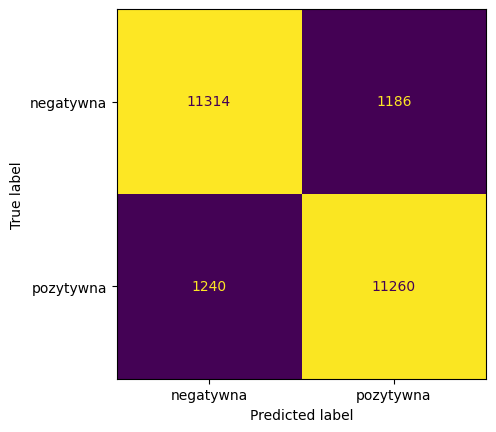

              precision    recall  f1-score   support

   negatywna      0.901     0.905     0.903     12500
   pozytywna      0.905     0.901     0.903     12500

    accuracy                          0.903     25000
   macro avg      0.903     0.903     0.903     25000
weighted avg      0.903     0.903     0.903     25000



In [7]:
# Twoje rozwiązanie

from sklearn.metrics import ConfusionMatrixDisplay, classification_report

model_koncowy = gs.best_estimator_

X_test, y_test = test_df["text"], test_df["label"]
y_pred = model_koncowy.predict(X_test)

acc_test = model_koncowy.score(X_test, y_test)
print(f"accuracy (test): {acc_test:.3f}")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["negatywna", "pozytywna"], colorbar=False)
plt.show()

print(classification_report(y_test, y_pred, target_names=["negatywna", "pozytywna"], digits=3))


In [8]:
# TEST
assert 0.87 < acc_test < 0.93
print("4 OK")

4 OK


---
## 5. Co model „wie” i gdzie się myli
1. Z `model_koncowy` wyciągnij nazwy cech (`model_koncowy[0].get_feature_names_out()`) i wagi (`model_koncowy[-1].coef_[0]`) do `pd.Series` o nazwie `wagi`. Wypisz po 15 cech o największej i najmniejszej wadze. Czy są wśród nich bigramy?
2. `bledy` – `DataFrame` z recenzjami testowymi, które model sklasyfikował źle (kolumny `text`, `label`, `pred`). Wypisz liczbę błędów i przeczytaj **3 przykłady** (pierwsze 500 znaków).
3. Napisz **5 własnych recenzji** (po angielsku), w tym co najmniej jedną z negacją i jedną ironiczną, i sprawdź predykcje modelu.

In [9]:
# Twoje rozwiązanie

# 1. najważniejsze cechy
slowa = model_koncowy[0].get_feature_names_out()
wagi = pd.Series(model_koncowy[-1].coef_[0], index=slowa).sort_values()
print("liczba cech:", len(wagi))

print("\nnajbardziej negatywne:")
print(wagi.head(15).round(3))
print("\nnajbardziej pozytywne:")
print(wagi.tail(15).round(3))

print("\nbigramy wśród nich:", [w for w in list(wagi.head(15).index) + list(wagi.tail(15).index) if " " in w])

# 2. błędy na teście
bledy = test_df.assign(pred=y_pred)[y_pred != y_test.values]
print("\nliczba błędów:", len(bledy))

for i in range(3):
    print(f"\n--- błąd {i + 1}: label = {bledy['label'].iloc[i]}, pred = {bledy['pred'].iloc[i]}")
    print(bledy["text"].iloc[i][:500])

# 3. własne recenzje
moje = [
    "One of the best movies I have ever seen, great story and amazing actors.",
    "The plot made no sense and the acting was terrible.",
    "I wouldn't say this film is bad, it was actually not bad at all.",
    "Oh great, another two hours of my life I will never get back. Truly a masterpiece.",
    "The first half was boring, but the ending was so good that I loved it.",
]
print()
for tekst, p, d in zip(moje, model_koncowy.predict(moje), model_koncowy.decision_function(moje)):
    print(f"pred = {p}  (wynik {d:+.2f})   {tekst}")


liczba cech: 436597

najbardziej negatywne:
worst            -4.187
awful            -3.718
bad              -3.640
boring           -3.461
poor             -3.270
the worst        -3.183
waste            -2.919
disappointment   -2.605
terrible         -2.583
worse            -2.567
poorly           -2.511
disappointing    -2.463
dull             -2.420
unfortunately    -2.396
annoying         -2.333
dtype: float64

najbardziej pozytywne:
best         1.835
favorite     1.854
bit          1.856
loved        1.876
superb       1.906
brilliant    1.945
the best     1.955
enjoyable    1.965
today        2.204
amazing      2.208
fun          2.286
wonderful    2.566
perfect      2.752
excellent    3.237
great        3.571
dtype: float64

bigramy wśród nich: ['the worst', 'the best']

liczba błędów: 2426

--- błąd 1: label = 0, pred = 1
First off let me say, If you haven't enjoyed a Van Damme movie since bloodsport, you probably will not like this movie. Most of these movies may not have th

In [10]:
# TEST
assert len(wagi) > 100_000, "Słownik powinien zawierać bigramy"
assert set(bledy.columns) >= {"text", "label", "pred"} and len(bledy) == (y_pred != y_test.values).sum()
assert any(" " in w for w in wagi.head(50).index) or any(" " in w for w in wagi.tail(50).index)
print("5 OK")

5 OK


1. Jakie bigramy znalazły się wśród najważniejszych cech? Co mówią o tym, czego model się nauczył?
2. Opisz trzy przeczytane błędy: dlaczego model mógł się pomylić? Czy człowiek też miałby wątpliwości?
3. Które z Twoich recenzji model ocenił źle? Co mają wspólnego?
4. Gdzie leży granica podejścia „worek słów + model liniowy”? Co musiałby umieć model, żeby poradzić sobie z Twoimi trudnymi przykładami?

*Twoja odpowiedź:*
1. „The worst” i „the best”. Model nauczył się rozpoznawać nie tylko pojedyncze słowa, ale też krótkie wyrażenia o określonym wydźwięku.
2. Model pomylił recenzje, w których pozytywne słowa występowały w negatywnym kontekście. Człowiek też mógłby mieć problem z ich oceną.
3. Najgorzej ocenił recenzje z negacją, ironią i konstrukcją „but”. Ich znaczenie zależy od całego zdania.
4. Model nie rozumie dobrze kontekstu i ironii. Musiałby analizować kolejność słów i znaczenie całych zdań, a nie tylko pojedyncze słowa.